# Json

In [1]:
import json
import pprint
import numpy as np
import matplotlib
import sys
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
import umap
from matplotlib import pyplot as plt


c:\Users\ACER\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
df=pd.read_csv(r"C:\Users\ACER\Desktop\UNIVERSITAS DOCTUS\Notas OneNote\Programación\Tesis\Encoder-xAI-LLMs\data\raw\scopus1_export_Jun 13-2026_08.csv")
print(len(df))
#df.columns
#df.head()
df["text"] = (
    df["Title"].fillna("") +
    ". " +
    df["Abstract"].fillna("") +
    ". " +
    df["Author Keywords"].fillna("")
)

910


In [10]:
df.info()
df.isna().sum()
print(len(df[df["Abstract"].notna()]))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 910 entries, 0 to 909
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Authors            884 non-null    object 
 1   Author full names  884 non-null    object 
 2   Author(s) ID       884 non-null    object 
 3   Title              910 non-null    object 
 4   Year               910 non-null    int64  
 5   Source title       910 non-null    object 
 6   Volume             529 non-null    object 
 7   Issue              232 non-null    object 
 8   Art. No.           248 non-null    object 
 9   Page start         476 non-null    float64
 10  Page end           476 non-null    float64
 11  Cited by           910 non-null    int64  
 12  DOI                830 non-null    object 
 13  Link               910 non-null    object 
 14  Abstract           910 non-null    object 
 15  Author Keywords    802 non-null    object 
 16  Index Keywords     767 non

# Transformer

In [11]:
model=SentenceTransformer(
    "all-MiniLM-L6-v2"
)
# Instancia el modelo.
embeddings=model.encode( # Genera los embeddings.
    df["text"].tolist(),
    # como df es de pandas al extraer una columna te devuelve un objeto pandas.core.series (serie de pandas [lista con indices])
    # Queremos que la lista con indices se convierta solo en una lista ["asd","asd"]
    # El método model.encode() esta diseñado para recibir str o list[str]
    show_progress_bar=True
)
# 1 Tokenizar. El texto entra al tokenizer (se fragmenta y se asigna un identificador numérico a cada fragmento)
# 2 Vectorizar. El encoder produce representaciones. El transformer genera un vector para cada token (código de identificación)
# 3 Atención y contexto. Después de varias capas "causal" no tiene la misma representación que "causal inference". Los demás tokens modifican su vector mediante atención.
# 4 Pooling. En (2-3) se trabaja a nivel token, En (4) "promediamos" para tener un único vector para todo el artículo?
# 5 Proyección. Agrupa todo en una matriz (30, 384). Cada elemento tiene un vector de 384 dimensiones cuyo significado desconocemos.
embeddings.shape

Batches: 100%|██████████| 29/29 [00:53<00:00,  1.85s/it]


(910, 384)

model.encode([t1,t2,t3]) Dice que se tiene que procesar la secuencia A, secuencia B, secuencia C. No dice que A es un artículo, B es una oración o C un argumento. La clave está en qué recibe encode. Siempre te devolverá un vector por una secuencia.

Una prueba interesante sería tomar uno de los artículos y fragmentarlo en título, abstract y título_abstract para generar embeddings por separado y comparar la similitud coseno en cada caso.

In [30]:
titulo=df["title"][0]
abst=df['abstract'][0]
titabs=df['text'][0]
todo=titulo,abst,titabs
emb_sep=model.encode(todo,show_progress_bar=True)


#print(titulo)
#print(abst)
#print(titabs)


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches: 100%|██████████| 1/1 [00:00<00:00,  4.15it/s]


In [36]:
from sklearn.metrics.pairwise import cosine_similarity
# print(emb_sep[0])

sim1=cosine_similarity(emb_sep)
#print(sim1)
labels = ["titulo", "abstract", "titulo+abstract"]

for i in range(3):
    for j in range(3):
        print(
            labels[i],
            "vs",
            labels[j],
            "=",
            round(sim1[i][j],3)
        )

titulo vs titulo = 1.0
titulo vs abstract = 0.602
titulo vs titulo+abstract = 0.677
abstract vs titulo = 0.602
abstract vs abstract = 1.0
abstract vs titulo+abstract = 0.971
titulo+abstract vs titulo = 0.677
titulo+abstract vs abstract = 0.971
titulo+abstract vs titulo+abstract = 1.0


# Similitudes con referencia

In [18]:
from sklearn.metrics.pairwise import cosine_similarity

sim = cosine_similarity(embeddings)
# Mide el ángulo entre dos puntos del espacio semántico.
# En embeddings suele importar más la dirección semántica que la distancia.
# sim es un objeto tipo <class 'numpy.ndarray'> de dimensión (30, 30)
# Hay 30 vectores, cada uno con 1 vector de 30 unidades.
# En el vector 1 hay un vector de 30 dimensiones. En la 1,1 está el ángulo entre ellos. En 1,2 el ángulo entre ellos.
sim.shape
# en sim[0] tengo como se compara el articulo 1 con todos los demas (y consigo mismo.)
#print(type(sim[0]))
#print(sim[0])

(910, 910)

In [19]:
df.iloc[0]["Title"]

'Enforcing Accountability in Autonomous Ops: A Zero-Trust Multi-Agent Framework With Forensic Reasoning Ledgers'

In [21]:

indices = np.argsort(sim[0])[::-1]

indices[:10]

array([  0, 199, 566, 442, 882, 127, 297, 604, 326, 363])

In [23]:
for i in indices[:10]:
    print()
    print(round(sim[0][i],3))
    print(df.iloc[i]["Title"])


1.0
Enforcing Accountability in Autonomous Ops: A Zero-Trust Multi-Agent Framework With Forensic Reasoning Ledgers

0.661
Graph of Agentic Thoughts: Bridging Agentic Reasoning and Explainability through Graphs

0.652
AI-Driven Zero-Trust Cloud Security: Automated Threat Response Leveraging Multi-Cloud Data Lakes and LLMS

0.646
Trustworthy and Explainable LLM Security Frameworks

0.633
Agentic AI for Autonomous Defense in Software Supply Chain Security: Beyond Provenance to Vulnerability Mitigation

0.624
A Review of TRiSM Frameworks in Artificial Intelligence Systems: Fundamentals, Taxonomy, Use Cases, Key Challenges and Future Directions

0.623
Trustworthy AI in Design: Introducing Explainable Agent Systems

0.622
LLM-Guided Multi-Agent Collaboration for Complex Task Automation

0.614
Towards Explainable Multi-Agent Systems with GraphRAG: A Guide to Explain Explanations in the Audit Domain

0.61
LLM-Augmented Algorithmic Management: A Governance-Oriented Architecture for Explainable

In [25]:
idx = df[df["Title"].str.contains("Explainability")].index[0]
# Busca "Probing Classifiers" en títulos del df y obtiene lista booleana.
# Busca la lista booleana, encuentra un elemento y extrae el índice de ese elemento.
# idx cotniene el índice del artículo de referencia..
indices = np.argsort(sim[idx])[::-1] 
# sim es el resultado de cosine_similarities(embeddings). Es una matriz (30,30)
# El orden de sim es el mismo que el df. Cada fila de sim tiene los mismos indices que df.
# en sim[0] tengo como se compara el articulo 1 con todos los demas (y consigo mismo)
# Uso el índice idx para obtener la similitud respecto del articulo numero idx (referencia).
# [::-1] Invierte el orden de los valores por grado de similitud
# Argsort no devuelve los valores, devuelve los índices ordenados por grado de similitud.
#print(indices)
#for i in indices[:10]:
    # Ciclo que recorre los 10 más similares.
    #print(round(sim[idx][i],3)) # i es el indice en indices que ya está ordenado.
    # Round redondea.
    #print(df.iloc[i]["Title"])

# kmeans
Cluster por Kmeans

A diferencia de "centro del campo" no supone que haya un solo centro, sino que supone que hay varios.
Intenta responder ¿Qué familia de artículos existen? ¿Qué diferencias internas hay?

Formalmente calcula $\sum_i ||x_i-c_i||^2$ donde
- $x_i$ es el embedding del articulo
- $c_i$ es el centroide de su cluster.

In [26]:
from sklearn.cluster import KMeans
kmeans=KMeans(n_clusters=4,random_state=42)
df["cluster"]=kmeans.fit_predict(embeddings)
# Crea una columna cluster cuyo valor esta entre 0-3 (los n_clusters)
'''for c in sorted(df["cluster"].unique()):
    print("\nCLUSTER", c)

    subset = df[df["cluster"]==c]

    for titulo in subset["title"]:
        print("-", titulo)
'''

'for c in sorted(df["cluster"].unique()):\n    print("\nCLUSTER", c)\n\n    subset = df[df["cluster"]==c]\n\n    for titulo in subset["title"]:\n        print("-", titulo)\n'

kmeans.fit_predict(embeddings)

combina 2 operaciones:
1. fit. Primero K-means aprende los clusters.
    - kmeans.fit(embeddings)
    - Observa todos los embeddings e intenta encontrar 4 centroides (porque pusiste n_clusters=4)
2. predict()
    - kmeans.predict(embeddings)
    - Pregunt ¿Cuál de los 4 centroides está más cerca?

Resultado general:
- Genera un array. Este array lo puse en una columna nueva clusters.
- El array tiene un número entre 0-(n-1) donde $n$ es el número de clusters declarado en KMeans(n_clusters) 

## Elbow method.
Para calcular el número de clusters adecuado debemos saber ¿Qué tan lejos están los artículos de los centroides que les fueron asignados?

Entre más cerca estén unos puntos si asignamos un centroide la distancia promedio será pequña, por lo tanto la inercia baja.

Pero para calcular el número de clusters no sólo nos interesa minimizar la inercia.
- Si solo nos importara minimzar la inercia pondríamos 30 clusters y la inercia sería 0
- Cada articulo estarí con su centroide.

La pregunta es ¿A partir de qué punto agregar más clusters deja de aportar mucho?


In [27]:
inercias=[]
for k in range (1,11):
    km=KMeans(
        n_clusters=k,
        random_state=42
    )
    km.fit(embeddings)
    inercias.append(km.inertia_)
#print(inercias)
#print(len(inercias))
for k,i in enumerate(inercias,start=1):
    print(k,i)

1 564.1707153320312
2 540.6788330078125
3 525.348388671875
4 507.7684020996094
5 498.5105285644531
6 488.12322998046875
7 482.1178283691406
8 478.5152893066406
9 475.1063232421875
10 469.6563415527344


inertia_ mide: qué tan lejos están los puntos de su centroide (menos es mejor, PERO:)

1 16.020366668701172
2 14.766959190368652
3 13.721711158752441
4 12.407001495361328
5 11.566452026367188
6 10.898287773132324
7 10.505122184753418
8 9.854921340942383
9 9.21377944946289
10 8.395750045776367

Si calculamos las diferencias no hay un codo espectacular.
1→2   -1.25
2→3   -1.05
3→4   -1.31
4→5   -0.84
5→6   -0.67
6→7   -0.39
7→8   -0.65
8→9   -0.64
9→10  -0.82
- El corpus es pequeño
- Los temas están bastante mezclados.
- No existen clusters naturales separados.

coincide bastante con la literatura de XAI para NLP.
Muchos artículos son simultáneamente:
probing + causal
causal + counterfactual
probing + neuron analysis

una idea importante para tu tesis: el "mejor" número de clusters no es sólo una cuestión matemática; también es una cuestión interpretativa. Los embeddings te dan una geometría, pero eres tú quien decide si esa geometría corresponde a categorías conceptualmente interesantes. Esa tensión entre estructura geométrica y significado conceptual es precisamente el tipo de cuestión que aparece una y otra vez cuando intentamos interpretar representaciones en modelos de lenguaje.

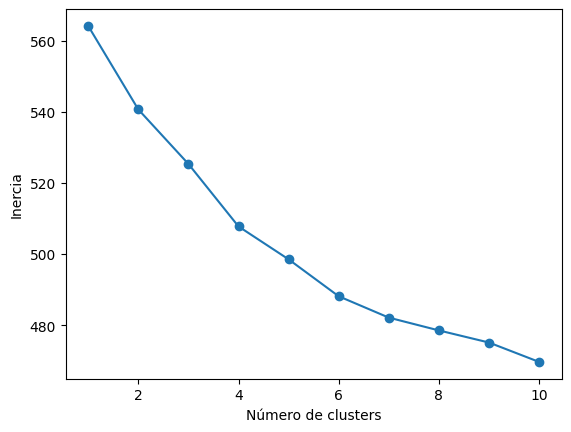

In [28]:
plt.plot(
    range(1,11),
    inercias,
    marker="o"
)
plt.xlabel("Número de clusters")
plt.ylabel("Inercia")
plt.show()

# Centro del campo
embeddings.mean(axis=0)
La función .mean es nativa de los objetos tipo sentencemodel. Promedia una dimension n del "articulo" x respecto de la misma dimensión n del resto de artículos x+1, x+2, ...

Supone que hay un sólo centro.
Intenta responder a ¿Qué tienen todos en común? mientras que kmeans ¿Qué diferencias internas hay?

Etiqueta:
for i,tit in enumerate(df["title"]):
    plt.annotate(
        str(i),
        (coords[i,0],coords[i,1])
    )


c:\Users\ACER\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


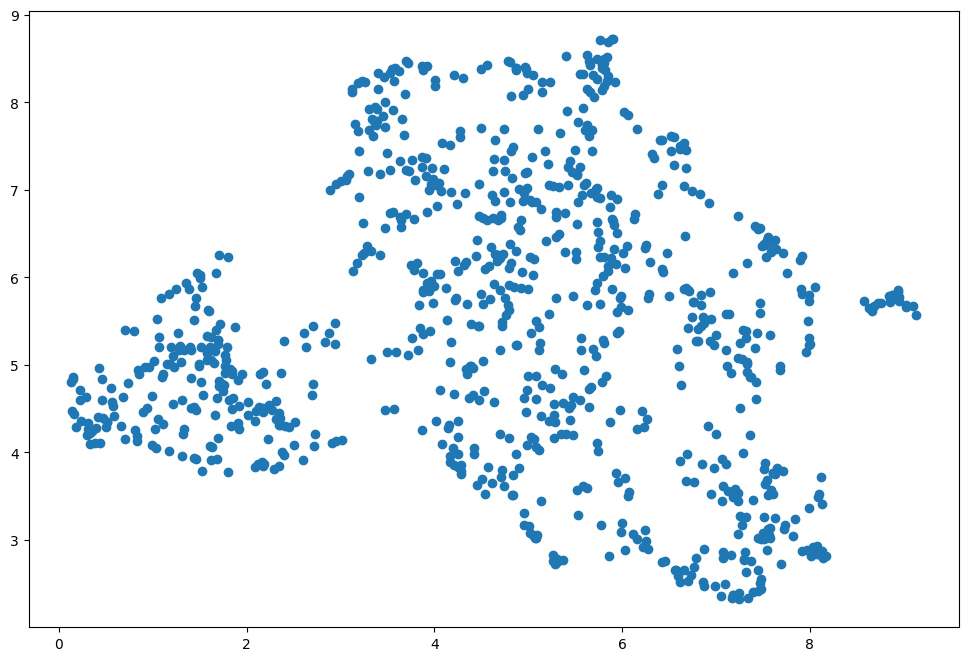

In [29]:
centro=embeddings.mean(axis=0)

sim_centro=cosine_similarity(embeddings,centro.reshape(1,-1))
reducer = umap.UMAP(
    random_state=42
)

coords = reducer.fit_transform(
    embeddings
)
#print(coords.shape)
plt.figure(figsize=(12,8))
plt.scatter(coords[:,0],coords[:,1])
plt.show()

# Comprobaciones
- ¿Realmente hay estructura? Miramos la matriz de similitud par abuscar clusters.
    - Que sea homogeneo tiene sentido porque no estamos comparando con fisica cuántica, historia medieval, economía, contr explicabilidad.


## Matriz sim
Análisis de matriz de similitud.
- Mapa de calor de similitud por pares (pairwise similarity heatmap)
    - a0 a1 a2 ...
      a0
      a1
      a2
      ...
    - Cada celda es la similitud coseno entre (a0,a1)
- Es esperable observar una diagonal resaltada porque son los casos de similitud que se comparan consigo mismos.
- Se observan patrones de similitud no aleatorios aunque sin bloques perfectamente definidos.

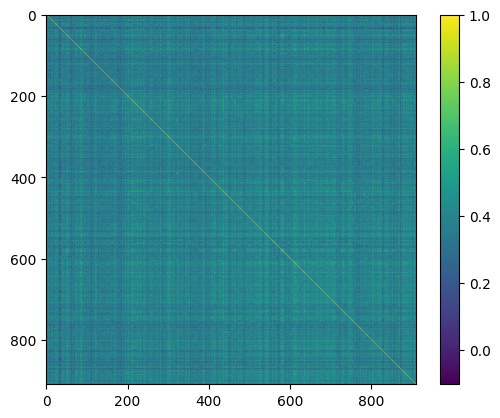

In [30]:
plt.imshow(sim)
plt.colorbar()
plt.show()

## Kmeans + UMAP

Identificar posibles agrupaciones temáticas en el corpus


c:\Users\ACER\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


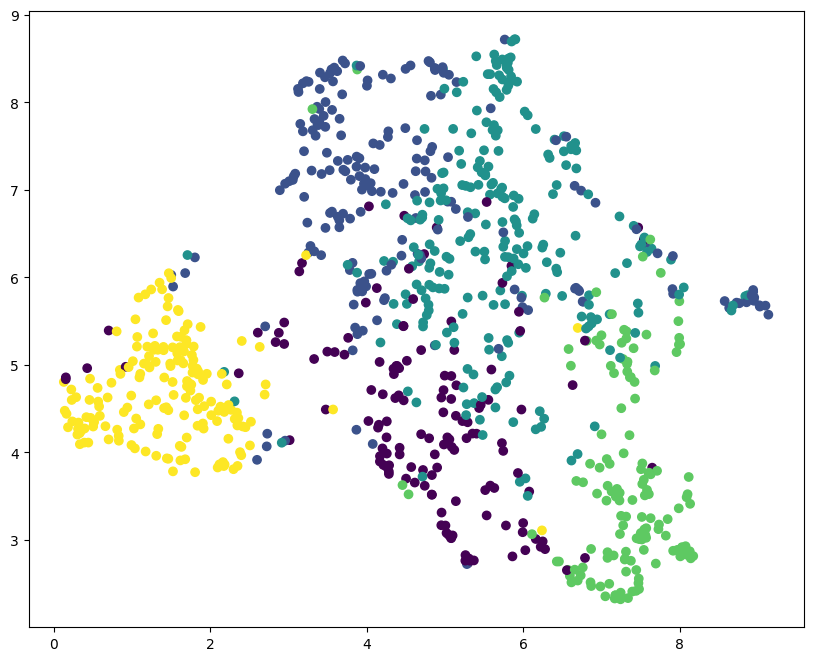

In [33]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=5,
    random_state=42
)

df["cluster"] = kmeans.fit_predict(
    embeddings
)
for c in sorted(df["cluster"].unique()):

    #print("\nCLUSTER", c)

    subset = df[df["cluster"] == c]

    #for titulo in subset["Title"].head(20):
        #print("-", titulo)
coords = umap.UMAP(
    random_state=42
).fit_transform(
    embeddings
)
plt.figure(figsize=(10,8))

plt.scatter(
    coords[:,0],
    coords[:,1],
    c=df["cluster"]
)

plt.show()

In [34]:
reducer = umap.UMAP(
    n_neighbors=5,
    min_dist=0.1,
    random_state=42
)
coords = reducer.fit_transform(
    embeddings
)
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.5,
    random_state=42
)

c:\Users\ACER\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


# Buscador semántico

In [48]:
query=model.encode("causal explanation methods")
score=cosine_similarity([query],embeddings)[0]
#print(score.shape)
reducer = umap.UMAP(
    random_state=42
)
indices = np.argsort(score)[::-1]

for i in indices[:10]:
    print(round(score[i],3))
    print(df.iloc[i]["Title"])
    print()


0.458
Causal-LLM: A Hybrid Framework for Automated Budgetary Variance Diagnosis and Reasoning

0.457
TAXAL framework: Triadic fusion of cognitive, functional, and causal dimensions for explainability in agentic LLMs

0.433
Explaining the 'Unexplainable' Large Language Models

0.425
Beyond Technical Transparency: Explainability as a Safeguard Against Manipulative AI

0.423
Causal What-Ifs: Rethinking Counterfactuals with LLM Agents

0.413
Crossing the Trust Gap in Medical AI: Building an Abductive Bridge for xAI

0.391
Can Large Language Models Act as Symbolic Reasoners?

0.387
AI Agents Powered by Open-Source Language Models for Causal Understanding in Portuguese

0.381
Fact or Fiction? Exploring Explanations to Identify Factual Confabulations in RAG-Based LLM Systems

0.372
Leveraging Human-aligned and Probabilistic AI for White-box Research and Knowledge Discovery: A Survey



## Colorear query

ValueError: 'c' argument has 910 elements, which is inconsistent with 'x' and 'y' with size 911.

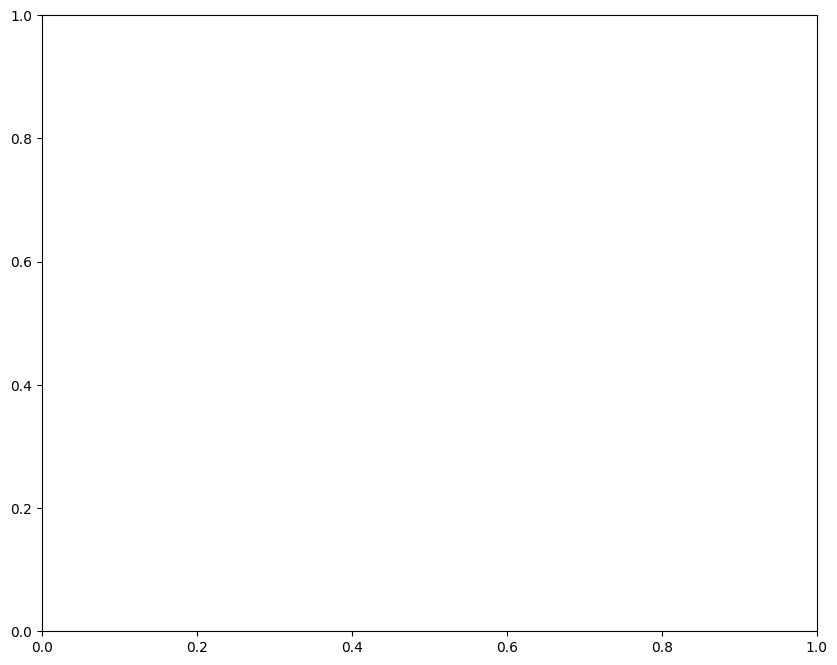

In [49]:
plt.figure(figsize=(10,8))

plt.scatter(
    coords[:,0],
    coords[:,1],
    c=score
)

plt.colorbar(label="Similitud con query")

plt.show()

## Dibujar query

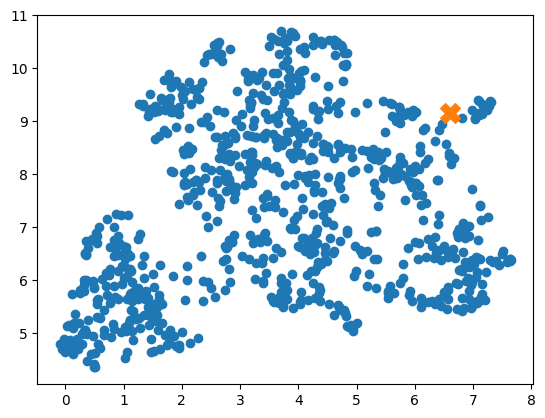

In [45]:
query = model.encode(
    "substructural logic"
)
todos = np.vstack([ # Agregas temporalmente el embedding de la query con el de la bibliografía
    embeddings,
    query
])
coords = reducer.fit_transform(todos)
coords.shape

plt.scatter(
    coords[:-1,0],
    coords[:-1,1]
)

plt.scatter(
    coords[-1,0],
    coords[-1,1],
    marker="X",
    s=200
)
'''for i,tit in enumerate(df["Title"]):
    plt.annotate(
        str(i),
        (coords[i,0],coords[i,1])
    )'''
plt.show()